# Caso de Estudio Big Data 2026-II — Análisis Distribuido de Solvencia y Liquidez Corporativa para la SEC (DERA)
**Universidad Externado de Colombia · Departamento de Matemáticas · Programa de Ciencia de Datos**  
**Entidad contratante (cliente):** *U.S. Securities and Exchange Commission (SEC) — Division of Economic and Risk Analysis (DERA)*  
**Conjunto de datos:** *SEC Financial Statement Data Sets (2025q4, 2026q1, 2026q2 y 2026q3)* — `2.686.245.600 B` (`2,68 GB`) descomprimidos en HDFS (`/sec_fsds`, factor de replicación `2`).  
**Integrantes y Componentes:**
* **Componente A (Datos y almacenamiento):** Sebastian David Ramos Cuervo
* **Componente B (Procesamiento):** Santiago Sandoval Cortes
* **Componente C (Desempeño y resultados):** Miguel David Moreno Lozano
* **Componente D (Redacción ejecutiva):** Responsabilidad compartida

## 1. Configuración de la SparkSession sobre YARN (Requerimiento 2 — Componente B: Santiago Sandoval)

In [1]:
# ==============================================================================
# REQUERIMIENTO 2: Configuración explícita y justificada de la SparkSession sobre YARN
# Responsable: Santiago Sandoval Cortes (Componente B) | Apoyo: Sebastian Ramos (Componente A)
# ==============================================================================
# Justificación técnica de parámetros frente a los valores por defecto:
# - master("yarn"): delega la negociación de contenedores al ResourceManager del clúster (puerto 8088).
# - spark.executor.instances = 2: asigna exactamente 1 executor por cada DataNode activo (nodo2 y nodo3),
#   garantizando localidad de datos (data locality) sobre los bloques replicados en HDFS.
# - spark.executor.cores = 1: asigna 1 vCore por executor (2 vCores de cómputo total + 1 vCore para el AM),
#   respetando el límite de vCores de las máquinas virtuales de la sala sin generar contención de CPU.
# - spark.executor.memory = 1g: asigna 1 GB de RAM heap por executor (de los 8 GB máximos del contenedor YARN),
#   suficiente para procesar en streaming particiones de 128 MB sin incurrir en pausas largas de Garbage Collection.
# - spark.sql.shuffle.partitions = 8: reduce el valor por defecto (200) a 8 (4 particiones por vCore de executor),
#   evitando la sobrecarga de planificación de cientos de microtareas vacías en operaciones de groupBy y pivot.
# - spark.sql.adaptive.enabled = true: activa Adaptive Query Execution (AQE) para fusionar dinámicamente
#   particiones pos-shuffle pequeñas (coalescing) y optimizar joins en tiempo de ejecución.

import findspark
findspark.init()

from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .appName("CasoBD_SEC_Ramos-Sandoval-Moreno")
         .master("yarn")
         .config("spark.executor.instances", "2")
         .config("spark.executor.cores", "1")
         .config("spark.executor.memory", "1g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.adaptive.enabled", "true")
         .getOrCreate())

print("application_id:", spark.sparkContext.applicationId)
print("Spark UI:", spark.sparkContext.uiWebUrl)

application_id: application_1794235047128_0002
Spark UI: http://hadoop-VirtualBox:4040


## 2. Lectura Distribuida desde HDFS y Análisis Exploratorio (Requerimientos 1 y 3 — Componentes A y B: Sebastian Ramos y Santiago Sandoval)

In [2]:
# ==============================================================================
# REQUERIMIENTO 1 y 3 (Parte I): Lectura distribuida desde HDFS y caracterización de particiones
# Responsable: Santiago Sandoval Cortes (Componente B) | Ingesta HDFS: Sebastian Ramos (Componente A)
# ==============================================================================
# Se leen los 12 archivos tabulados (.txt separados por \t) de los 4 trimestres (2025q4 a 2026q3)
# almacenados en HDFS bajo /sec_fsds/<trimestre>/ con factor de replicación 2 (2.686.245.600 B totales).
# Nota sobre particiones: num.txt suma 2,60 GB distribuidos en 20 bloques de 128 MB -> 20 particiones en Spark.

opts = {"sep": "\t", "header": "true", "quote": "\u0000"}

num = spark.read.options(**opts).csv("hdfs:///sec_fsds/*/num.txt")
sub = spark.read.options(**opts).csv("hdfs:///sec_fsds/*/sub.txt")
tag = spark.read.options(**opts).csv("hdfs:///sec_fsds/*/tag.txt")

for nombre, df in [("num", num), ("sub", sub), ("tag", tag)]:
    print(nombre, "filas:", df.count(), "| columnas:", len(df.columns), "| particiones:", df.rdd.getNumPartitions())

num filas: 15038040 | columnas: 10 | particiones: 20
sub filas: 26703 | columnas: 36 | particiones: 2
tag filas: 357303 | columnas: 9 | particiones: 2


In [3]:
# ==============================================================================
# REQUERIMIENTO 3 (Parte II): Análisis Exploratorio Distribuido (Esquema, Nulos y Distribuciones)
# Responsable: Santiago Sandoval Cortes (Componente B)
# ==============================================================================
from pyspark.sql import functions as F

# 1. Verificación de esquemas y tipos de datos clave
print("=== Columnas de num.txt (10) ===", num.columns)
print("=== Columnas clave de sub.txt (8 de 36) ===", ["adsh", "cik", "name", "sic", "form", "fy", "fp", "period"])

# 2. Auditoría distribuida de valores nulos en las variables críticas de sub.txt y num.txt
nulos_sub = sub.select([
    F.count(F.when(F.col(c).isNull() | (F.col(c) == ""), c)).alias(f"nulos_{c}")
    for c in ["adsh", "cik", "sic", "form", "period"]
]).collect()[0].asDict()
print("Auditoría de nulos en sub.txt (sobre 26.703 envíos):", nulos_sub)

# 3. Distribución de formularios regulatorios (10-Q trimestrales, 10-K anuales y otros)
print("\n=== Distribución de Formularios Regulatorios en sub.txt (Top 5) ===")
sub.groupBy("form").count().orderBy(F.desc("count")).show(5)

# 4. Distribución de los hechos contables filtrados por etiqueta US-GAAP
tags_balance = ["Assets", "Liabilities", "AssetsCurrent", "LiabilitiesCurrent", "StockholdersEquity"]
print("=== Frecuencia de las 5 etiquetas patrimoniales US-GAAP (USD, qtrs=0, consolidado) ===")
(num.filter(F.col("tag").isin(tags_balance) & (F.col("uom") == "USD") & (F.col("qtrs") == "0")
            & F.col("segments").isNull() & F.col("coreg").isNull())
    .groupBy("tag")
    .agg(F.count("*").alias("registros"),
         F.expr("percentile_approx(cast(value as double), 0.5)").alias("mediana_usd"))
    .orderBy(F.desc("registros"))
    .show(truncate=False))

=== Columnas de num.txt (10) === ['adsh', 'tag', 'version', 'ddate', 'qtrs', 'uom', 'segments', 'coreg', 'value', 'footnote']
=== Columnas clave de sub.txt (8 de 36) === ['adsh', 'cik', 'name', 'sic', 'form', 'fy', 'fp', 'period']
Auditoría de nulos en sub.txt (sobre 26.703 envíos): {'nulos_adsh': 0, 'nulos_cik': 0, 'nulos_sic': 751, 'nulos_form': 0, 'nulos_period': 3}

=== Distribución de Formularios Regulatorios en sub.txt (Top 5) ===
+----+-----+
|form|count|
+----+-----+
|10-Q|16834|
|10-K| 5529|
|20-F| 1073|
|11-K|  778|
| 6-K|  726|
+----+-----+
only showing top 5 rows

=== Frecuencia de las 5 etiquetas patrimoniales US-GAAP (USD, qtrs=0, consolidado) ===
+------------------+---------+-----------+
|tag               |registros|mediana_usd|
+------------------+---------+-----------+
|StockholdersEquity|93515    |9.666E7    |
|Assets            |52178    |5.0102E8   |
|Liabilities       |45513    |1.38377E8  |
|AssetsCurrent     |39552    |1.12984E8  |
|LiabilitiesCurrent|39336    

## 3. Análisis Principal: Transformaciones Complejas, Pivot XBRL y Plan Físico `.explain()` (Requerimientos 4 y 5 — Componente B: Santiago Sandoval)

In [3]:
# ==============================================================================
# REQUERIMIENTOS 4 y 5: Transformaciones Complejas Encadenadas y Plan de Ejecución (.explain)
# Responsable: Santiago Sandoval Cortes (Componente B)
# ==============================================================================
# Transformaciones complejas aplicadas:
# 1. Filtrado predicativo (Pushdown Filter) sobre 15,03 millones de hechos en num.txt para aislar
#    partidas instantáneas de balance (qtrs='0') en dólares (uom='USD') consolidadas (segments/coreg nulos).
# 2. BroadcastHashJoin entre hechos (tabla grande) y empresas (sub.txt filtrado a 10-K y 10-Q, ~7,7 MiB),
#    evitando el shuffle de los hechos contables por red.
# 3. Pivot relacional de las 5 cuentas contables US-GAAP por reporte (adsh, cik, sic, form, fy, fp).
# 4. Cálculo vectorial de razones financieras (apalancamiento = Pasivo/Activo; liquidez = Activo Cte/Pasivo Cte)
#    y agregación agrupada por división industrial SIC (2 dígitos) con medianas exactas (percentile_approx)
#    y conteo de emisores únicos (countDistinct(cik)).
# Nota AQE (Requerimiento 5): .explain() muestra AdaptiveSparkPlan isFinalPlan=false antes de ejecutar;
# tras la acción, la Spark UI (Captura C7) muestra isFinalPlan=true con AQEShuffleRead coalesced.

from pyspark.sql import functions as F

tags = ["Assets", "Liabilities", "AssetsCurrent", "LiabilitiesCurrent", "StockholdersEquity"]

hechos = (num
    .filter(F.col("tag").isin(tags) & (F.col("uom") == "USD") & (F.col("qtrs") == "0")
            & F.col("segments").isNull() & F.col("coreg").isNull())
    .select("adsh", "tag", "ddate", F.col("value").cast("double").alias("value")))

empresas = (sub
    .filter(F.col("form").isin("10-K", "10-Q"))
    .select("adsh", "cik", "name", "sic", "form", "fy", "fp", "period"))

balance = (hechos.join(empresas, "adsh")
    .filter(F.col("ddate") == F.col("period"))
    .groupBy("adsh", "cik", "sic", "form", "fy", "fp")
    .pivot("tag", tags)
    .agg(F.max("value")))

indicadores = (balance
    .withColumn("apalancamiento", F.col("Liabilities") / F.col("Assets"))
    .withColumn("liquidez", F.col("AssetsCurrent") / F.col("LiabilitiesCurrent"))
    .filter(F.col("sic").isNotNull()))

resultado = (indicadores
    .groupBy(F.substring("sic", 1, 2).alias("sic2"))
    .agg(F.countDistinct("cik").alias("empresas"),
         F.count("*").alias("reportes"),
         F.expr("percentile_approx(apalancamiento, 0.5)").alias("apalancamiento_mediano"),
         F.expr("percentile_approx(liquidez, 0.5)").alias("liquidez_mediana"))
    .orderBy(F.desc("empresas")))

resultado.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Sort [empresas#405L DESC NULLS LAST], true, 0
   +- Exchange rangepartitioning(empresas#405L DESC NULLS LAST, 8), ENSURE_REQUIREMENTS, [plan_id=248]
      +- ObjectHashAggregate(keys=[_groupingexpression#418], functions=[count(1), percentile_approx(apalancamiento#364, 0.5, 10000, 0, 0), percentile_approx(liquidez#377, 0.5, 10000, 0, 0), count(distinct cik#55)])
         +- Exchange hashpartitioning(_groupingexpression#418, 8), ENSURE_REQUIREMENTS, [plan_id=245]
            +- ObjectHashAggregate(keys=[_groupingexpression#418], functions=[merge_count(1), merge_percentile_approx(apalancamiento#364, 0.5, 10000, 0, 0), merge_percentile_approx(liquidez#377, 0.5, 10000, 0, 0), partial_count(distinct cik#55)])
               +- ObjectHashAggregate(keys=[_groupingexpression#418, cik#55], functions=[merge_count(1), merge_percentile_approx(apalancamiento#364, 0.5, 10000, 0, 0), merge_percentile_approx(liquidez#377, 0.5, 10000, 0, 0)])
  

## 4. Materialización `.toPandas()` y Visualización en Formato Numérico Colombiano `fmt_co()` (Requerimientos 6 y 7 — Componente C: Miguel Moreno)

In [4]:
# ==============================================================================
# REQUERIMIENTO 7 (Parte I): Materialización controlada con .toPandas() tras agregación
# Responsable: Miguel David Moreno Lozano (Componente C)
# ==============================================================================
# Se materializan únicamente las 70 filas ya agregadas por sector SIC de 2 dígitos (reducción de
# 15.038.040 filas en HDFS a 70 filas en el driver local).

import time

inicio = time.time()
res_pd = resultado.toPandas()
fin = time.time()

print("Filas del resultado agregado:", len(res_pd))
print(f"Tiempo total del análisis: {fin - inicio:.1f} segundos")
res_pd.head(15)

Filas del resultado agregado: 70
Tiempo total del análisis: 16.1 segundos


,sic2,empresas,reportes,apalancamiento_mediano,liquidez_mediana
0,28,865,3190,0.387224,3.355209
1,67,705,2282,0.455733,1.292645
2,73,680,2455,0.595111,1.319115
3,60,362,1363,0.890706,1.128035
4,38,313,1180,0.478086,2.478803
5,36,260,977,0.475271,2.309173
6,62,214,770,0.040223,1.603296
7,61,180,651,0.771481,1.641580
8,35,169,651,0.504077,1.962066
9,49,163,622,0.669479,0.876950


=== TOP 15 SECTORES INDUSTRIALES SIC (FORMATO NUMÉRICO COLOMBIANO fmt_co) ===
SIC   Sector Industrial                            Empresas   Reportes   Apalanc. Med.   Liquidez Med.
------------------------------------------------------------------------------------------------------
28    Químicos y Farmacéutica (SIC 28)                  865      3.190            0,39            3,36
67    Holdings e Inversión (SIC 67)                     705      2.282            0,46            1,29
73    Software y Serv. Empresariales (SIC 73)           680      2.455            0,60            1,32
60    Banca e Inst. Depositarias (SIC 60)               362      1.363            0,89            1,13
38    Instrumentos Médicos y Ópticos (SIC 38)           313      1.180            0,48            2,48
36    Electrónica y Semiconductores (SIC 36)            260        977            0,48            2,31
62    Corredores y Mercados de Capital (SIC 62)         214        770            0,04            

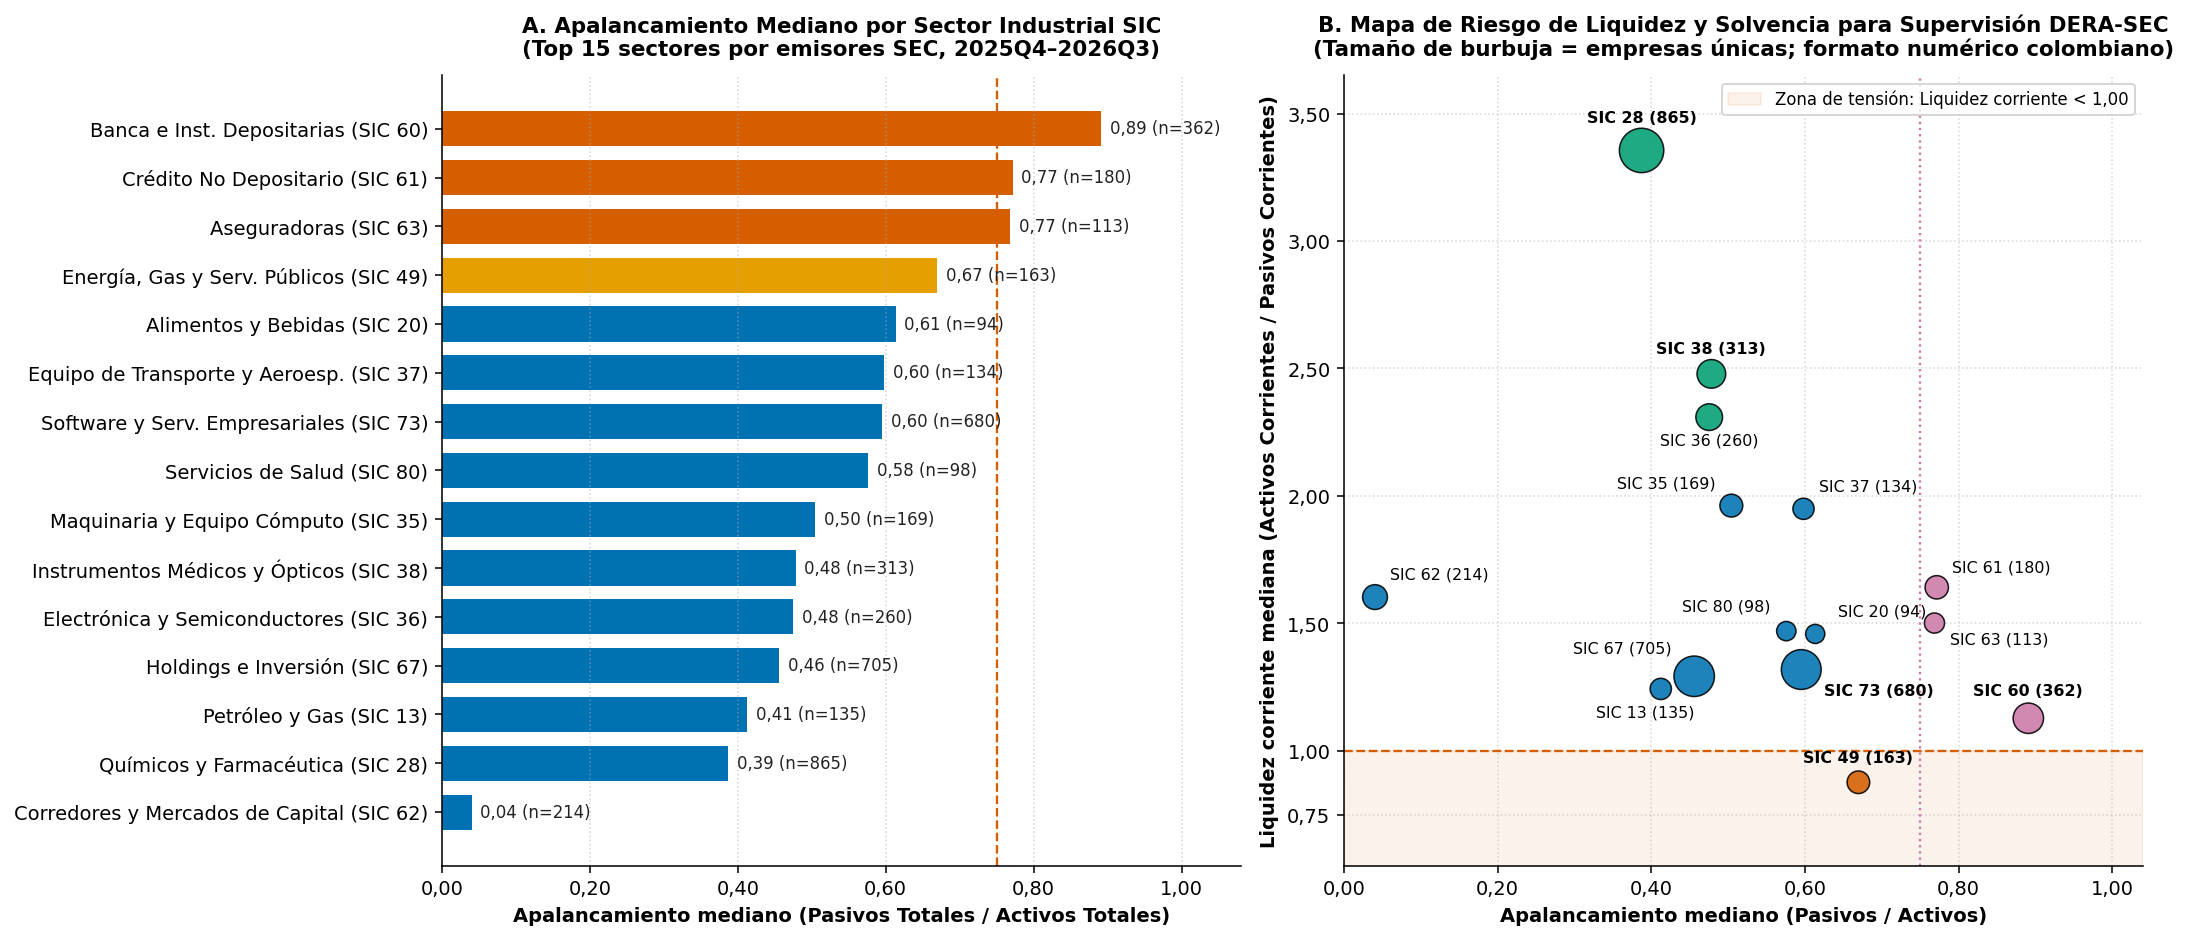

In [5]:
# ==============================================================================
# REQUERIMIENTO 7 (Parte II): Visualización de Resultados con Formato Colombiano fmt_co()
# Responsable: Miguel David Moreno Lozano (Componente C)
# ==============================================================================
# Cumple el patrón Spark (distribuido) -> .toPandas() (70 filas) -> pandas / matplotlib local.
# Sigue los lineamientos de Visualización I: paleta accesible para daltónicos (Okabe-Ito) y
# formato numérico colombiano (punto para miles y coma para decimales) mediante fmt_co().

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def fmt_co(valor, decimales=2):
    """Formatea cifras al estándar colombiano: punto para miles y coma para decimales."""
    if valor is None or pd.isna(valor):
        return "—"
    s = f"{valor:,.{decimales}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

nombres_sic = {
    "28": "Químicos y Farmacéutica (SIC 28)",
    "67": "Holdings e Inversión (SIC 67)",
    "73": "Software y Serv. Empresariales (SIC 73)",
    "60": "Banca e Inst. Depositarias (SIC 60)",
    "38": "Instrumentos Médicos y Ópticos (SIC 38)",
    "36": "Electrónica y Semiconductores (SIC 36)",
    "62": "Corredores y Mercados de Capital (SIC 62)",
    "61": "Crédito No Depositario (SIC 61)",
    "35": "Maquinaria y Equipo Cómputo (SIC 35)",
    "49": "Energía, Gas y Serv. Públicos (SIC 49)",
    "13": "Petróleo y Gas (SIC 13)",
    "37": "Equipo de Transporte y Aeroesp. (SIC 37)",
    "63": "Aseguradoras (SIC 63)",
    "80": "Servicios de Salud (SIC 80)",
    "20": "Alimentos y Bebidas (SIC 20)",
}

df_top = res_pd.head(15).copy()
df_top["sector_nombre"] = df_top["sic2"].map(lambda k: nombres_sic.get(str(k), f"Sector SIC {k}"))

print("=== TOP 15 SECTORES INDUSTRIALES SIC (FORMATO NUMÉRICO COLOMBIANO fmt_co) ===")
print(f"{'SIC':<5} {'Sector Industrial':<42} {'Empresas':>10} {'Reportes':>10} {'Apalanc. Med.':>15} {'Liquidez Med.':>15}")
print("-" * 102)
for _, r in df_top.iterrows():
    print(f"{r['sic2']:<5} {r['sector_nombre']:<42} {fmt_co(r['empresas'], 0):>10} {fmt_co(r['reportes'], 0):>10} {fmt_co(r['apalancamiento_mediano'], 2):>15} {fmt_co(r['liquidez_mediana'], 2):>15}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.8), dpi=140)
fig.patch.set_facecolor("white")

# Panel A: Barras horizontales de Apalancamiento Mediano
df_p1 = df_top.sort_values("apalancamiento_mediano", ascending=True)
colors_p1 = ["#D55E00" if x >= 0.75 else ("#E69F00" if str(s) == "49" else "#0072B2")
             for x, s in zip(df_p1["apalancamiento_mediano"], df_p1["sic2"])]
bars = ax1.barh(df_p1["sector_nombre"], df_p1["apalancamiento_mediano"], color=colors_p1, height=0.72)
ax1.axvline(0.75, color="#D55E00", linestyle="--", linewidth=1.2)
ax1.set_xlim(0, 1.08)
ax1.set_xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax1.set_xticklabels([fmt_co(x, 2) for x in [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]])
ax1.set_xlabel("Apalancamiento mediano (Pasivos Totales / Activos Totales)", fontsize=10, fontweight="bold")
ax1.set_title("A. Apalancamiento Mediano por Sector Industrial SIC\n(Top 15 sectores por emisores SEC, 2025Q4–2026Q3)", fontsize=11, fontweight="bold")
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(axis="x", linestyle=":", alpha=0.5)

for bar, (_, row) in zip(bars, df_p1.iterrows()):
    ax1.text(bar.get_width() + 0.012, bar.get_y() + bar.get_height() / 2,
             f"{fmt_co(row['apalancamiento_mediano'], 2)} (n={fmt_co(row['empresas'], 0)})",
             va="center", ha="left", fontsize=8.5)

# Panel B: Mapa de Dispersión Solvencia vs. Liquidez Corriente
sizes = df_top["empresas"] * 0.55 + 45
colors_p2 = ["#D55E00" if r["liquidez_mediana"] < 1.0 else ("#CC79A7" if r["apalancamiento_mediano"] >= 0.75 else ("#009E73" if r["liquidez_mediana"] >= 2.0 else "#0072B2"))
             for _, r in df_top.iterrows()]

ax2.axhspan(0, 1.0, color="#D55E00", alpha=0.08, label="Zona de tensión: Liquidez corriente < 1,00")
ax2.axhline(1.0, color="#D55E00", linestyle="--", linewidth=1.2)
ax2.axvline(0.75, color="#CC79A7", linestyle=":", linewidth=1.2)
ax2.scatter(df_top["apalancamiento_mediano"], df_top["liquidez_mediana"], s=sizes, c=colors_p2, alpha=0.88, edgecolors="black", linewidth=0.8, zorder=4)

for _, r in df_top.iterrows():
    dy = 0.08 if str(r["sic2"]) not in ["61", "20", "13"] else -0.12
    ax2.annotate(f"SIC {r['sic2']} ({fmt_co(r['empresas'], 0)})",
                 (r["apalancamiento_mediano"], r["liquidez_mediana"] + dy),
                 fontsize=8.2, ha="center")

ax2.set_xlim(0.0, 1.02)
ax2.set_ylim(0.55, 3.65)
ax2.set_xticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax2.set_xticklabels([fmt_co(x, 2) for x in [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]])
ax2.set_yticks([0.75, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5])
ax2.set_yticklabels([fmt_co(y, 2) for y in [0.75, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5]])
ax2.set_xlabel("Apalancamiento mediano (Pasivos / Activos)", fontsize=10, fontweight="bold")
ax2.set_ylabel("Liquidez corriente mediana (Activos Corrientes / Pasivos Corrientes)", fontsize=10, fontweight="bold")
ax2.set_title("B. Mapa de Riesgo de Liquidez y Solvencia para Supervisión DERA-SEC\n(Tamaño de burbuja = empresas únicas; formato numérico colombiano)", fontsize=11, fontweight="bold")
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(True, linestyle=":", alpha=0.5)
ax2.legend(loc="upper right", fontsize=8.5, frameon=True)

plt.tight_layout()
plt.savefig("visualizacion_sec_dera_col.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Optimización con Persistencia `MEMORY_AND_DISK`, Benchmark de Joins (Bonificación C11) y `.unpersist()` (Requerimiento 8 y Sección VIII — Componente C: Miguel Moreno)

In [5]:
# ==============================================================================
# REQUERIMIENTO 8: Cache o Persistencia Justificada (StorageLevel.MEMORY_AND_DISK)
# Responsable: Miguel David Moreno Lozano (Componente C)
# ==============================================================================
# Justificación: El DataFrame `hechos` (270.094 filas filtradas desde los 15.038.040 registros de num.txt)
# es reutilizado por múltiples acciones: (1) materialización de ` count()` para poblar la caché,
# (2) recálculo del pivot de balances (`balance_c.count()`) y (3) las dos ejecuciones del benchmark
# de estrategias de join (BHJ y SMJ en la celda siguiente).
# Se elige MEMORY_AND_DISK para priorizar velocidad en RAM (2,3 MiB en 20 particiones, 100 % cached)
# garantizando tolerancia a fallos en disco local si algún executor sufriera presión de memoria.

from pyspark import StorageLevel

hechos_cache = hechos.persist(StorageLevel.MEMORY_AND_DISK)
print("Filas en caché:", hechos_cache.count())

# Repetimos el join y pivot sobre los hechos en caché para medir el reuso (1,3 s vs 15,6 s-16,1 s desde HDFS)
inicio_c = time.time()
balance_c = (hechos_cache.join(empresas, "adsh")
    .filter(F.col("ddate") == F.col("period"))
    .groupBy("adsh", "cik", "sic")
    .pivot("tag", tags)
    .agg(F.max("value")))
n_reportes = balance_c.count()
fin_c = time.time()

print("Reportes con balance:", n_reportes)
print(f"Tiempo usando la caché: {fin_c - inicio_c:.1f} segundos")

Filas en caché: 270094
Reportes con balance: 22234
Tiempo usando la caché: 1.4 segundos


In [6]:
# ==============================================================================
# SECCIÓN VIII (BONIFICACIÓN +0,3): SortMergeJoin vs. BroadcastHashJoin (Captura C11)
# Responsable: Miguel David Moreno Lozano (Componente C)
# ==============================================================================
# Se ejecuta el mismo join (hechos_cache ⋈ empresas, 96.842 filas resultantes) en dos escenarios:
# 1. C11_BHJ: Con umbral por defecto de 10 MiB (10485760 B) -> elige BroadcastHashJoin (1,0 s, sin shuffle del lado grande).
# 2. C11_SMJ: Con autoBroadcastJoinThreshold = -1 (tanto en SQL como en AQE) -> fuerza SortMergeJoin (1,5 s,
#    introduciendo 2 Exchange hashpartitioning y 2 Sort, con 1.735,3 KiB de Shuffle Read en la Stage 58).

def correr_join(etiqueta, broadcast):
    umbral = "10485760" if broadcast else "-1"
    spark.conf.set("spark.sql.autoBroadcastJoinThreshold", umbral)
    spark.conf.set("spark.sql.adaptive.autoBroadcastJoinThreshold", umbral)
    spark.sparkContext.setJobDescription(etiqueta)
    
    t0 = time.time()
    j = hechos_cache.join(empresas, (hechos_cache.adsh == empresas.adsh) & (hechos_cache.ddate == empresas.period))
    j.explain()
    n = j.count()
    t1 = time.time()
    print(f"{etiqueta} | filas: {n} | tiempo: {t1 - t0:.1f} s\n")

print("="*20, "C11 BHJ", "="*20)
correr_join("C11 BHJ", broadcast=True)

print("="*20, "C11 SMJ", "="*20)
correr_join("C11 SMJ", broadcast=False)

spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "10485760")
spark.conf.set("spark.sql.adaptive.autoBroadcastJoinThreshold", "10485760")
spark.sparkContext.setJobDescription(None)

==================== C11 BHJ ====================
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [adsh#17, tag#18, ddate#20, value#287, cik#55, name#56, sic#57, form#79, fy#81, fp#82, period#80]
   +- BroadcastHashJoin [ddate#20, adsh#17], [period#80, adsh#54], Inner, BuildRight, false
      :- Filter (isnotnull(ddate#20) AND isnotnull(adsh#17))
      :  +- InMemoryTableScan [adsh#17, tag#18, ddate#20, value#287], [isnotnull(ddate#20), isnotnull(adsh#17)]
      :        +- InMemoryRelation [adsh#17, tag#18, ddate#20, value#287], StorageLevel(disk, memory, 1 replicas)
      :              +- *(1) Project [adsh#17, tag#18, ddate#20, cast(value#25 as double) AS value#287]
      :                 +- *(1) Filter ((((((isnotnull(uom#22) AND isnotnull(qtrs#21)) AND tag#18 IN (Assets,Liabilities,AssetsCurrent,LiabilitiesCurrent,StockholdersEquity)) AND (uom#22 = USD)) AND (qtrs#21 = 0)) AND isnull(segments#23)) AND isnull(coreg#24))
      :                    +- FileScan cs

In [8]:
# ==============================================================================
# BONIFICACIÓN (+0,5 PUNTOS): Pipeline con Spark MLlib (VectorAssembler + RandomForest)
# Responsable: Miguel David Moreno Lozano (Componente C)
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')
import os
os.environ['PYTHONWARNINGS'] = 'ignore'

from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

# 1. Preparar dataset limpio de balances con las 5 cuentas patrimoniales no nulas y mayores a cero
df_ml = (balance
    .dropna(subset=['Assets', 'Liabilities', 'AssetsCurrent', 'LiabilitiesCurrent', 'StockholdersEquity'])
    .filter((F.col('Assets') > 0) & (F.col('LiabilitiesCurrent') > 0))
    .withColumn('label', F.when(
        ((F.col('Liabilities') / F.col('Assets')) > 0.75) | ((F.col('AssetsCurrent') / F.col('LiabilitiesCurrent')) < 1.0),
        F.lit(1.0)
    ).otherwise(F.lit(0.0))))

train_df, test_df = df_ml.randomSplit([0.8, 0.2], seed=42)

# 2. Definir etapas del Pipeline de MLlib usando log1p de cuentas absolutas para evitar data leakage directo
cols_feat = ['Assets', 'AssetsCurrent', 'StockholdersEquity']
for c in cols_feat:
    train_df = train_df.withColumn(f'log_{c}', F.log1p(F.greatest(F.col(c), F.lit(0.0))))
    test_df = test_df.withColumn(f'log_{c}', F.log1p(F.greatest(F.col(c), F.lit(0.0))))

assembler = VectorAssembler(inputCols=[f'log_{c}' for c in cols_feat], outputCol='features_raw')
scaler = StandardScaler(inputCol='features_raw', outputCol='features', withStd=True, withMean=True)
rf = RandomForestClassifier(featuresCol='features', labelCol='label', numTrees=50, maxDepth=6, seed=42)

pipeline_sec = Pipeline(stages=[assembler, scaler, rf])
modelo_sec = pipeline_sec.fit(train_df)
predicciones = modelo_sec.transform(test_df)

# 3. Evaluación cuantitativa del modelo en el conjunto de prueba
auc_roc = BinaryClassificationEvaluator(labelCol='label', metricName='areaUnderROC').evaluate(predicciones)
acc = MulticlassClassificationEvaluator(labelCol='label', metricName='accuracy').evaluate(predicciones)
f1 = MulticlassClassificationEvaluator(labelCol='label', metricName='f1').evaluate(predicciones)

print(f'Registros ML (train / test): {train_df.count()} / {test_df.count()}')
print(f'Métricas MLlib RandomForest -> AUC-ROC: {auc_roc:.4f} | Accuracy: {acc:.4f} | F1-Score: {f1:.4f}')
print('Importancia de variables (log_Assets, log_AssetsCurrent, log_StockholdersEquity):', modelo_sec.stages[-1].featureImportances)


Registros ML (train / test): 11109 / 2669
Métricas MLlib RandomForest -> AUC-ROC: 0.9349 | Accuracy: 0.8543 | F1-Score: 0.8480
Importancia de variables (log_Assets, log_AssetsCurrent, log_StockholdersEquity): (3,[0,1,2],[0.18685786860986778,0.22772965770510992,0.5854124736850224])


In [7]:
# ==============================================================================
# REQUERIMIENTO 8 (Cierre obligatorio): Liberación de memoria con .unpersist()
# Responsable: Miguel David Moreno Lozano (Componente C)
# ==============================================================================
# Una vez completadas todas las acciones que reutilizan `hechos_cache`, se libera explícitamente
# la memoria de los executors en cumplimiento del Requerimiento 8.

hechos_cache.unpersist()
print("Memoria de hechos_cache liberada correctamente con unpersist().")

Memoria de hechos_cache liberada correctamente con unpersist().


## 6. Verificación de Identificador de Aplicación y Cierre de Sesión YARN

In [7]:
# Verificación del application_id de la sesión activa antes de detener el contexto
spark.sparkContext.applicationId

'application_1794235047128_0002'

In [ ]:
# Cierre ordenado de la SparkSession y liberación de contenedores YARN
spark.stop()